In [2]:
import numpy as np, matplotlib.pyplot as plt, statsmodels.api as sm
from scipy.optimize import minimize
nile = sm.datasets.nile.load_pandas().data
year = nile.year.astype(int).values; y = nile.volume.values.astype(float)       # y[0] is the measurement of 1871
print(len(y), "annual measurements,", year[0], "to", year[-1], "(units: 10^8 m^3)")

100 annual measurements, 1871 to 1970 (units: 10^8 m^3)


In [3]:
def kalman_filter(y, Q, R, m0, P0):
    """Scalar Kalman filter (Theorem 6.6 with A = H = 1).  y[k] = NaN means no measurement that year."""
    n = len(y); m, P, m_, P_, K = (np.full(n, np.nan) for _ in range(5))
    S = np.full(n, np.nan); loglik = 0.0; mk, Pk = m0, P0
    for k in range(n):
        mk_ = mk                                     
        Pk_ = Pk + Q                                 
        if np.isfinite(y[k]):
            v = y[k] - mk_       
            S[k] = Pk_ + R       
            K[k] = Pk_ / S[k]     
            mk = mk_ + K[k] * v                              
            Pk = Pk_ - K[k] * S[k] * K[k]            
            loglik += -0.5 * (np.log(2 * np.pi * S[k]) + v * v / S[k])
        else:
            mk, Pk = mk_, Pk_                        
        m[k], P[k], m_[k], P_[k] = mk, Pk, mk_, Pk_
    return dict(m=m, P=P, m_=m_, P_=P_, K=K, S=S, loglik=loglik)

In [4]:
m0, P0 = 1000.0, 1e7  
Q, R = 1500.0, 15000.0
out = kalman_filter(y, Q, R, m0, P0); m, P = out["m"], out["P"]

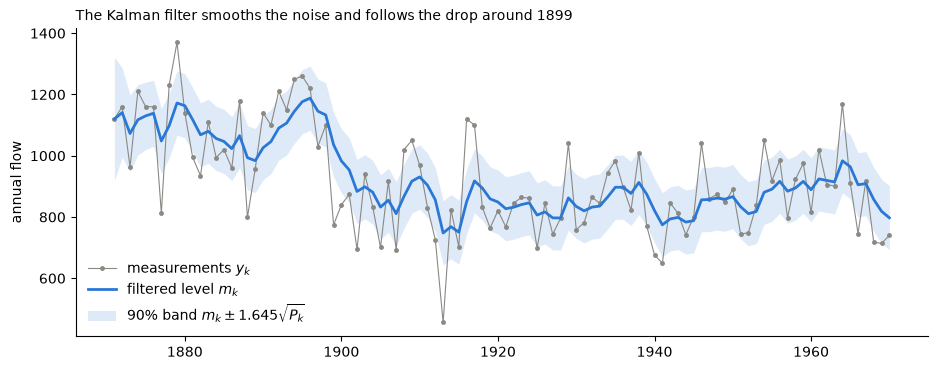

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(year, y, ".-", color="#8a8984", ms=5, lw=.8, label="measurements $y_k$")
ax.plot(year, m, color="#2a78d6", lw=2, label="filtered level $m_k$")
ax.fill_between(year, m - 1.645 * np.sqrt(P), m + 1.645 * np.sqrt(P), color="#2a78d6", alpha=.15, lw=0, label="90% band $m_k\\pm1.645\\sqrt{P_k}$")
ax.set_ylabel("annual flow"); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("The Kalman filter smooths the noise and follows the drop around 1899", loc="left", fontsize=10); plt.show()

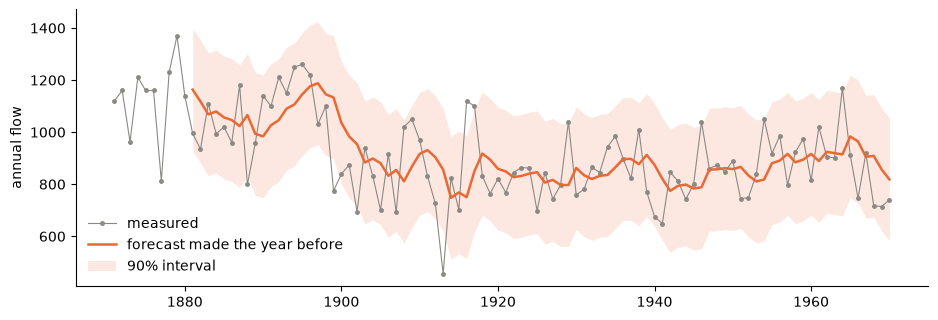

In [6]:
mean, sd = out["m_"], np.sqrt(out["P_"] + R)                 
ok = np.arange(len(y)) >= 10                                

fig, ax = plt.subplots(figsize=(11, 3.6)); ax.plot(year, y, ".-", color="#8a8984", ms=5, lw=.8, label="measured")
ax.plot(year[ok], mean[ok], color="#eb6834", lw=1.8, label="forecast made the year before")
ax.fill_between(year[ok], (mean - 1.645 * sd)[ok], (mean + 1.645 * sd)[ok], color="#eb6834", alpha=.15, lw=0, label="90% interval")
ax.legend(frameon=False); ax.set_ylabel("annual flow"); ax.spines[["top", "right"]].set_visible(False); plt.show()